# Phase 3 — Satellite Space-Time Coincidence Analysis

**Project:** *How Often Would a Satellite Have Warned You?* — retrospective satellite
space-time coincidence analysis for hazardous sea states along the Lisbon–Halifax
North Atlantic shipping corridor (base paper: Kytariolou & Themelis, 2022,
*Journal of Navigation* 75(6)).

For every hazardous sea-state event catalogued along the route, this notebook checks
whether a **Sentinel-1 SAR acquisition** or an **altimeter pass** was coincident within
±`DELTA_T_HOURS` and `DELTA_X_KM`, then computes coincidence probabilities and a
preliminary forecast-bias check.

| Hypothesis | Statement | Section |
|---|---|---|
| **H1** | Coincidence is low for a single SAR mission and rises with the full constellation + altimeters | 3.4 |
| **H2** | Coincidence is spatially heterogeneous: higher near the Grand Banks (≈ 40–55°N, 40–55°W) than mid-Atlantic | 3.4 |
| **H3** | The CMEMS model underestimates peak Hs at coincident events | 3.5 |

> **Runs on the 2022 test subset by default.** Change `YEAR_START` / `YEAR_END` at the
> top of Cell 1 for a multi-year run. Local files in `Wave_Reanalysis/` and
> `L3_altimetry/` are used when present; otherwise data is streamed with
> `copernicusmarine` (credentials from `CMEMS_USERNAME` / `CMEMS_PASSWORD`).
>
> Smoke test without data or network: `jupyter nbconvert --to script phase3_coincidence.ipynb`
> then `python phase3_coincidence.py --dry-run`.

In [1]:
# ── Dependencies
# Installs the notebook requirements into the running kernel's environment.
# Uses subprocess (not %pip) so the exported .py script also runs in plain Python.
# Set INSTALL_DEPS = False once your environment is ready; skipped under --dry-run.
import subprocess
import sys

INSTALL_DEPS = True
PACKAGES = ["copernicusmarine", "pystac-client", "requests", "numpy", "pandas", "xarray",
            "netCDF4", "shapely", "pyproj", "matplotlib", "tqdm", "pyarrow", "ipython"]

if INSTALL_DEPS and "--dry-run" not in sys.argv:
    try:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *PACKAGES])
    except Exception as exc:
        print(f"[deps] pip install failed ({exc}); continuing with the installed packages.")

# ── Cell 1: imports and configuration


In [10]:
# All imports + the CONFIG block. Paths are relative to the notebook folder
# (Jupyter starts the kernel there). DRY_RUN (--dry-run flag or PHASE3_DRY_RUN=1)
# defines every function but skips all data access and network calls.
import json
import os
import sys
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib

DRY_RUN = "--dry-run" in sys.argv or os.getenv("PHASE3_DRY_RUN") == "1"
if DRY_RUN:
    matplotlib.use("Agg")  # no GUI window when run as a plain script
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import shapely.geometry as sgeom
from shapely import wkt as swkt
from pyproj import Geod
from pystac_client import Client
import copernicusmarine
from tqdm.auto import tqdm
from IPython.display import display

warnings.filterwarnings("ignore", category=RuntimeWarning)

# ── Paths (relative to this notebook's folder)
BASE_DIR = Path.cwd()
DATA_DIR = BASE_DIR / "data"
FIG_DIR = BASE_DIR / "figures"
WAVE_LOCAL_DIR = BASE_DIR / "Wave_Reanalysis"   # pre-downloaded CMEMS wave reanalysis (.nc)
ALT_LOCAL_DIR = BASE_DIR / "L3_altimetry"       # pre-downloaded L3 altimeter SWH (.csv)
for _d in (DATA_DIR, FIG_DIR):
    _d.mkdir(exist_ok=True)

# ════════════════════════════ CONFIG ════════════════════════════
# ── Study area
ROUTE_LONS = np.linspace(-9.1, -63.6, 60)   # Lisbon → Halifax
ROUTE_LATS = np.linspace(38.7,  44.7, 60)   # approximate great-circle

# ── Time range (change to multi-year when ready)
YEAR_START, YEAR_END = 2010, 2020

# ── Coincidence window
DELTA_T_HOURS = 3.0          # temporal half-window [h]
DELTA_X_KM    = 200.0        # spatial radius [km]

# ── SAR catalogue endpoint
CDSE_STAC_URL = "https://catalogue.dataspace.copernicus.eu/stac"
# The legacy "SENTINEL-1" collection no longer exists on this endpoint; Level-2 OCN
# products (IW/EW + WV) are the wave-relevant Sentinel-1 collections.
SAR_COLLECTIONS = ["sentinel-1-ocn", "sentinel-1-ocn-wv"]
STAC_PAUSE_S = 1.0           # pause between STAC requests (CDSE rate-limits with HTTP 429)

# ── CMEMS credentials (read from environment variables)
CMEMS_USER = os.getenv("CMEMS_USERNAME", "YOUR_USERNAME")
CMEMS_PASS = os.getenv("CMEMS_PASSWORD", "YOUR_PASSWORD")
WAVE_DATASET_ID = "cmems_mod_glo_wav_my_0.2deg_PT3H-i"
ALT_DATASET_ID = "cmems_obs-wave_glo_phy-swh_my_multi-l3_PT1S"

# ── Safety thresholds (from ship_physics.py / paper Table 1)
HEAVE_THRESH_M  = 3.5
ROLL_THRESH_DEG = 5.0
ABNORMALITY_IDX = 2.0
ABNORMALITY_WINDOW_STEPS = 240   # 30-day running-mean baseline (240 × 3 h) for the Hs proxy

# ── Corridor segments used in H2 / ADV
GRAND_BANKS_LON = (-55.0, -45.0)
MID_ATLANTIC_LON = (-40.0, -20.0)
LON_EDGES = np.arange(-64.0, -8.0, 5.0)     # 5° bands: [-64,-59], ..., [-14,-9]

# ── Re-use existing data/*.parquet checkpoints when they cover every event
REUSE_CHECKPOINTS = True
# ════════════════════════════════════════════════════════════════

GEOD = Geod(ellps="WGS84")


def cmems_credentials():
    """Explicit credentials if the env vars are set, else let copernicusmarine use its stored login."""
    if CMEMS_USER == "YOUR_USERNAME" or CMEMS_PASS == "YOUR_PASSWORD":
        return {}
    return {"username": CMEMS_USER, "password": CMEMS_PASS}


# Cross-check the thresholds against the Phase 1 module
try:
    sys.path.insert(0, str(BASE_DIR))
    from ship_physics import ship_physics as sp
    if (sp.HEAVE_THRESHOLD_SIG_M, sp.ROLL_THRESHOLD_SIG_DEG, sp.ABNORMALITY_INDEX) != \
            (HEAVE_THRESH_M, ROLL_THRESH_DEG, ABNORMALITY_IDX):
        print("[config] WARNING: thresholds differ from ship_physics.py")
except Exception as exc:
    print(f"[config] ship_physics not importable ({exc}); using the CONFIG thresholds.")

print(f"Years {YEAR_START}-{YEAR_END} | Δt = ±{DELTA_T_HOURS} h | Δx = {DELTA_X_KM} km | "
      f"route nodes = {len(ROUTE_LONS)} | DRY_RUN = {DRY_RUN}")

Years 2010-2020 | Δt = ±3.0 h | Δx = 200.0 km | route nodes = 60 | DRY_RUN = False


## 3.1 Load Hazard Event Catalogue

Load the geolocated, timestamped hazard events produced by Phase 2
(`data/hazard_catalogue_{year}.parquet`). If that file is not available yet, the
catalogue is built inline from the CMEMS wave reanalysis:

1. Hs (`VHM0`) and peak period (`VTPK`) are interpolated onto the 60 route nodes at every 3-hourly step.
2. A **simplified hazard proxy** is applied: `Hs > HEAVE_THRESH_M` *or* `Hs / Hs_30day-mean > ABNORMALITY_IDX`.
   The full Phase 1 flag (heave + roll RAO + Hmax/Hs abnormality) is to be plugged in later.
3. Consecutive flagged 3-h steps at the same node are merged into **one event**, located at its peak-Hs time
   (otherwise a single storm would count as dozens of correlated events).

In [11]:
# ── Section 3.1: hazard catalogue
# Loads data/hazard_catalogue_{year}.parquet, or builds it from the CMEMS wave reanalysis
# (local NetCDF in Wave_Reanalysis/ first, copernicusmarine streaming as fallback).
# One row per event = one run of consecutive flagged 3-h steps at one route node.
CATALOGUE_COLUMNS = ["event_id", "datetime", "lon", "lat", "Hs_cmems", "T0_cmems", "flag_reason",
                     "route_node", "n_steps", "event_start", "event_end"]


def open_wave_dataset(year):
    """CMEMS wave reanalysis for one year: local NetCDF if present, else copernicusmarine (lazy)."""
    local = sorted(WAVE_LOCAL_DIR.glob(f"{WAVE_DATASET_ID}*_{year}-01-01-{year}-12-31.nc"))
    if local:
        print(f"[wave] {year}: using local file {local[0].name}")
        return xr.open_dataset(local[0])
    try:
        print(f"[wave] {year}: streaming {WAVE_DATASET_ID} with copernicusmarine")
        return copernicusmarine.open_dataset(
            dataset_id=WAVE_DATASET_ID, variables=["VHM0", "VTPK"],
            minimum_longitude=float(ROUTE_LONS.min()) - 1, maximum_longitude=float(ROUTE_LONS.max()) + 1,
            minimum_latitude=float(ROUTE_LATS.min()) - 1, maximum_latitude=float(ROUTE_LATS.max()) + 1,
            start_datetime=f"{year}-01-01T00:00:00", end_datetime=f"{year}-12-31T23:59:59",
            **cmems_credentials())
    except Exception as exc:
        print(f"[wave] {year}: copernicusmarine download failed: {exc}")
        return None


def interp_to_route(da, route_lons, route_lats):
    """Bilinear interpolation onto route nodes; nodes next to land fall back to the nearest cell."""
    pts = dict(longitude=xr.DataArray(route_lons, dims="node"),
               latitude=xr.DataArray(route_lats, dims="node"))
    return da.interp(**pts).fillna(da.sel(**pts, method="nearest")).load()


def build_hazard_catalogue_year(year, route_lons, route_lats):
    """Inline build of one year's catalogue (simplified Hs proxy flag + event declustering)."""
    ds = open_wave_dataset(year)
    if ds is None:
        return pd.DataFrame(columns=CATALOGUE_COLUMNS)
    hs = interp_to_route(ds["VHM0"], route_lons, route_lats)
    # VTPK is not in the pre-downloaded file; fall back to the primary-swell mean period
    t0_var = next((v for v in ("VTPK", "VTM10", "VTM01_SW1") if v in ds), None)
    if t0_var != "VTPK":
        print(f"[wave] {year}: VTPK not available, T0_cmems taken from {t0_var}")
    t0 = interp_to_route(ds[t0_var], route_lons, route_lats) if t0_var else hs * np.nan
    ds.close()

    # Hazard flag — simplified proxy (Phase 1 full flag to be plugged in: heave + roll RAO + Hmax/Hs).
    # The spec's Hs.rolling(time=1) baseline equals Hs itself (ratio always 1), so a 30-day
    # running mean is used as the "normal sea state" for the abnormality ratio.
    baseline = hs.rolling(time=ABNORMALITY_WINDOW_STEPS, center=True, min_periods=1).mean()
    heave = (hs > HEAVE_THRESH_M).values
    abnormal = ((hs / baseline) > ABNORMALITY_IDX).values
    flag = heave | abnormal

    times = pd.to_datetime(hs["time"].values)
    step = pd.Timedelta(hours=3)
    hs_v, t0_v = hs.values, t0.values
    rows = []
    for j in range(len(route_lons)):
        padded = np.r_[False, flag[:, j], False]
        starts = np.flatnonzero(~padded[:-1] & padded[1:])
        ends = np.flatnonzero(padded[:-1] & ~padded[1:])        # exclusive
        for s, e in zip(starts, ends):
            k = s + int(np.nanargmax(hs_v[s:e, j]))
            reasons = [name for name, m in (("heave_proxy", heave), ("abnormality", abnormal)) if m[s:e, j].any()]
            rows.append(dict(datetime=times[k], lon=float(route_lons[j]), lat=float(route_lats[j]),
                             Hs_cmems=float(hs_v[k, j]), T0_cmems=float(t0_v[k, j]),
                             flag_reason="+".join(reasons), route_node=j, n_steps=int(e - s),
                             event_start=times[s], event_end=times[e - 1] + step))
    cat = pd.DataFrame(rows).sort_values(["datetime", "route_node"]).reset_index(drop=True)
    cat.insert(0, "event_id", [f"{year}-{i:05d}" for i in range(len(cat))])
    return cat[CATALOGUE_COLUMNS]


def load_or_build_hazard_catalogue(year_start, year_end, route_lons, route_lats):
    """Phase 2 parquet per year if present, otherwise build inline and save it."""
    parts = []
    for year in range(year_start, year_end + 1):
        path = DATA_DIR / f"hazard_catalogue_{year}.parquet"
        if path.exists():
            print(f"[catalogue] {year}: loaded {path.name}")
            parts.append(pd.read_parquet(path))
            continue
        try:
            cat = build_hazard_catalogue_year(year, route_lons, route_lats)
        except Exception as exc:
            print(f"[catalogue] {year}: inline build failed: {exc}")
            continue
        if len(cat):
            cat.to_parquet(path, index=False)
            print(f"[catalogue] {year}: built {len(cat)} events → {path.name}")
        parts.append(cat)
    parts = [p for p in parts if len(p)]
    return pd.concat(parts, ignore_index=True) if parts else pd.DataFrame(columns=CATALOGUE_COLUMNS)


if DRY_RUN:
    catalogue = pd.DataFrame(columns=CATALOGUE_COLUMNS)
else:
    catalogue = load_or_build_hazard_catalogue(YEAR_START, YEAR_END, ROUTE_LONS, ROUTE_LATS)
print(f"Total hazard events: {len(catalogue)}")
if len(catalogue):
    print(catalogue["flag_reason"].value_counts().to_string())
display(catalogue.head())

[catalogue] 2010: loaded hazard_catalogue_2010.parquet
[catalogue] 2011: loaded hazard_catalogue_2011.parquet
[catalogue] 2012: loaded hazard_catalogue_2012.parquet
[catalogue] 2013: loaded hazard_catalogue_2013.parquet
[catalogue] 2014: loaded hazard_catalogue_2014.parquet
[catalogue] 2015: loaded hazard_catalogue_2015.parquet
[catalogue] 2016: loaded hazard_catalogue_2016.parquet
[catalogue] 2017: loaded hazard_catalogue_2017.parquet
[catalogue] 2018: loaded hazard_catalogue_2018.parquet
[catalogue] 2019: loaded hazard_catalogue_2019.parquet
[catalogue] 2020: loaded hazard_catalogue_2020.parquet
Total hazard events: 444229
flag_reason
heave_proxy                393801
heave_proxy+rogue_proxy     50428


,event_id,datetime,lon,lat,Hs_cmems,T0_cmems,U10_era5,flag_heave,flag_rogue,flag_any,route_seg_idx,lon_bin,flag_reason
0,2010_00000,2010-01-01 00:00:00+00:00,-10.023729,38.801695,4.878824,11.118315,13.551921,True,False,True,1,-15_-10,heave_proxy
1,2010_00001,2010-01-01 00:00:00+00:00,-10.947458,38.903390,4.896354,11.053218,13.671790,True,False,True,2,-15_-10,heave_proxy
2,2010_00002,2010-01-01 00:00:00+00:00,-11.871186,39.005085,5.035092,11.035939,14.589107,True,False,True,3,-15_-10,heave_proxy
3,2010_00003,2010-01-01 00:00:00+00:00,-12.794915,39.106780,5.142152,11.123848,14.930325,True,False,True,4,-15_-10,heave_proxy
4,2010_00004,2010-01-01 00:00:00+00:00,-13.718644,39.208475,5.142118,11.075331,14.571289,True,False,True,5,-15_-10,heave_proxy


In [12]:
# read parquet with the hazard catalogue
hazard_catalogue = pd.read_parquet("C:\\Users\\Tessa Mati\\OneDrive - Politecnico di Torino\\Desktop\\COP_hackathon\\data\\hazard_catalogue_2012.parquet")
hazard_catalogue.head()

,event_id,datetime,lon,lat,Hs_cmems,T0_cmems,U10_era5,flag_heave,flag_rogue,flag_any,route_seg_idx,lon_bin,flag_reason
0,2012_00000,2012-01-01 00:00:00+00:00,-31.269492,41.140678,3.585409,14.373137,10.664509,True,False,True,24,-35_-30,heave_proxy
1,2012_00001,2012-01-01 00:00:00+00:00,-32.193220,41.242373,3.824926,14.193477,11.029681,True,False,True,25,-35_-30,heave_proxy
2,2012_00002,2012-01-01 00:00:00+00:00,-33.116949,41.344068,4.075845,13.992400,11.447997,True,False,True,26,-35_-30,heave_proxy
3,2012_00003,2012-01-01 00:00:00+00:00,-34.040678,41.445763,4.323558,13.673221,11.925863,True,False,True,27,-35_-30,heave_proxy
4,2012_00004,2012-01-01 00:00:00+00:00,-34.964407,41.547458,4.473262,13.417589,11.795284,True,False,True,28,-35_-30,heave_proxy


## 3.2 Sentinel-1 SAR Acquisition Query

For each event the CDSE STAC catalogue is searched for Sentinel-1 Level-2 OCN products
(IW/EW and WV) within ±`DELTA_T_HOURS` and a `DELTA_X_KM` box; a product is **coincident**
when its footprint intersects a `DELTA_X_KM` buffer around the event.

To stay within CDSE rate limits, the catalogue is fetched **once per UTC day for the whole
corridor** and cached in `data/s1_items_cache.json`; per-event filtering is then done
locally with the same time-window / bbox / footprint logic. Re-running the cell only
re-requests days that previously failed. Note: Sentinel-1B was lost in Dec 2021, so 2022
is effectively a **single-SAR-mission** year (S1A only) — the baseline case for H1.

In [13]:
# ── Section 3.2: Sentinel-1 footprint coincidence
# Fetches S1 OCN items per day over the corridor (cached on disk), then tests each event
# for time overlap and footprint ∩ Δx-buffer. Output: one row per (event, S1 product);
# events with no product get a single placeholder row. Saved to data/sar_coincidence_raw.parquet.
SAR_COLUMNS = ["event_id", "sat_id", "item_id", "acq_time", "dt_hours", "sensor_mode", "orbit_direction",
               "footprint_wkt", "coincident", "query_ok"]
S1_CACHE_PATH = DATA_DIR / "s1_items_cache.json"
_s1_cache = json.loads(S1_CACHE_PATH.read_text()) if S1_CACHE_PATH.exists() else {}
_geom_cache = {}
_stac_client = None

_lat_pad = DELTA_X_KM / 111.0
_lon_pad = DELTA_X_KM / (111.0 * np.cos(np.radians(ROUTE_LATS.max() + _lat_pad)))
CORRIDOR_SAR_BBOX = [float(ROUTE_LONS.min() - _lon_pad), float(ROUTE_LATS.min() - _lat_pad),
                     float(ROUTE_LONS.max() + _lon_pad), float(ROUTE_LATS.max() + _lat_pad)]


def _utc_naive(value):
    ts = pd.Timestamp(value)
    return ts.tz_convert(None) if ts.tzinfo is not None else ts


def _item_to_record(item, collection):
    p = item.properties
    start = p.get("start_datetime") or p.get("datetime")
    return dict(item_id=item.id, collection=collection, sat_id=p.get("platform", item.id[:3]),
                sensor_mode=p.get("sar:instrument_mode"), orbit_direction=p.get("sat:orbit_state"),
                acq_start=start, acq_end=p.get("end_datetime") or start,
                footprint_wkt=sgeom.shape(item.geometry).wkt)


def _save_s1_cache():
    S1_CACHE_PATH.write_text(json.dumps(_s1_cache))


def _fetch_s1_day(day, stac_url, max_retries=4):
    """All S1 OCN items over the corridor for one UTC day → (records, ok). Cached in memory + on disk."""
    global _stac_client
    records, ok = [], True
    for col in SAR_COLLECTIONS:
        key = f"{col}|{day}"
        if key not in _s1_cache:
            for attempt in range(max_retries):
                try:
                    if _stac_client is None:
                        _stac_client = Client.open(stac_url)
                    search = _stac_client.search(collections=[col], bbox=CORRIDOR_SAR_BBOX,
                                                 datetime=f"{day}T00:00:00Z/{day}T23:59:59Z", limit=200)
                    _s1_cache[key] = [_item_to_record(it, col) for it in search.items()]
                    break
                except Exception as exc:
                    wait = STAC_PAUSE_S * 4 * 2 ** attempt
                    print(f"[stac] {key} attempt {attempt + 1}/{max_retries} failed: {str(exc)[:120]} "
                          f"— retrying in {wait:.0f}s")
                    time.sleep(wait)
            time.sleep(STAC_PAUSE_S)
            if len(_s1_cache) % 20 == 0:
                _save_s1_cache()
        if key in _s1_cache:
            records.extend(_s1_cache[key])
        else:
            ok = False
    return records, ok


def query_sentinel1_footprints(event_lon, event_lat, event_time, delta_t_h=DELTA_T_HOURS,
                               delta_x_km=DELTA_X_KM, stac_url=CDSE_STAC_URL, event_id=None):
    """S1 products inside the event's time window and bbox, flagged coincident if the
    footprint intersects the Δx buffer (1° ≈ 111 km)."""
    t = _utc_naive(event_time)
    t_start, t_end = t - pd.Timedelta(hours=delta_t_h), t + pd.Timedelta(hours=delta_t_h)
    dlat = delta_x_km / 111.0
    dlon = delta_x_km / (111.0 * np.cos(np.radians(event_lat)))
    bbox = sgeom.box(event_lon - dlon, event_lat - dlat, event_lon + dlon, event_lat + dlat)
    buffer = sgeom.Point(event_lon, event_lat).buffer(delta_x_km / 111.0)

    records, query_ok = [], True
    for day in pd.date_range(t_start.normalize(), t_end.normalize(), freq="D"):
        recs, ok = _fetch_s1_day(day.strftime("%Y-%m-%d"), stac_url)
        records.extend(recs)
        query_ok &= ok

    out, seen = [], set()
    for r in records:
        if r["item_id"] in seen:
            continue
        seen.add(r["item_id"])
        a0, a1 = _utc_naive(r["acq_start"]), _utc_naive(r["acq_end"])
        if a1 < t_start or a0 > t_end:
            continue
        geom = _geom_cache.get(r["item_id"])
        if geom is None:
            geom = _geom_cache[r["item_id"]] = swkt.loads(r["footprint_wkt"])
        if not geom.intersects(bbox):
            continue
        out.append(dict(event_id=event_id, sat_id=r["sat_id"], item_id=r["item_id"], acq_time=a0,
                        dt_hours=((a0 + (a1 - a0) / 2) - t) / pd.Timedelta(hours=1),
                        sensor_mode=r["sensor_mode"], orbit_direction=r["orbit_direction"],
                        footprint_wkt=r["footprint_wkt"], coincident=bool(geom.intersects(buffer)),
                        query_ok=query_ok))
    if not out:
        out.append(dict(event_id=event_id, coincident=False, query_ok=query_ok))
    return out


def _checkpoint_covers(path, cat):
    if not (REUSE_CHECKPOINTS and path.exists() and len(cat)):
        return None
    df = pd.read_parquet(path)
    return df if set(cat["event_id"]) <= set(df["event_id"]) else None


SAR_RAW_PATH = DATA_DIR / "sar_coincidence_raw.parquet"
if DRY_RUN:
    sar_results = pd.DataFrame(columns=SAR_COLUMNS)
elif (sar_results := _checkpoint_covers(SAR_RAW_PATH, catalogue)) is not None:
    sar_results = sar_results[sar_results["event_id"].isin(catalogue["event_id"])]
    print(f"[sar] re-using checkpoint {SAR_RAW_PATH.name}")
else:
    rows = []
    try:
        for ev in tqdm(catalogue.itertuples(index=False), total=len(catalogue), desc="Sentinel-1"):
            try:
                rows.extend(query_sentinel1_footprints(ev.lon, ev.lat, ev.datetime, event_id=ev.event_id))
            except Exception as exc:
                print(f"[sar] event {ev.event_id} failed: {exc}")
                rows.append(dict(event_id=ev.event_id, coincident=False, query_ok=False))
    finally:
        _save_s1_cache()
    sar_results = pd.DataFrame(rows, columns=SAR_COLUMNS)
    sar_results.to_parquet(SAR_RAW_PATH, index=False)

sar_results["coincident"] = sar_results["coincident"].astype("boolean").fillna(False).astype(bool)
sar_results["query_ok"] = sar_results["query_ok"].astype("boolean").fillna(False).astype(bool)
n_failed = sar_results.loc[~sar_results["query_ok"], "event_id"].nunique()
print(f"SAR queries (events): {sar_results['event_id'].nunique()} | products in window: "
      f"{sar_results['item_id'].notna().sum()} | coincident footprints: {sar_results['coincident'].sum()} | "
      f"events with ≥1 coincidence: {sar_results.loc[sar_results['coincident'], 'event_id'].nunique()}")
if n_failed:
    print(f"WARNING: {n_failed} events had a failed STAC day query (counted as non-coincident). "
          f"Delete {SAR_RAW_PATH.name} and re-run this cell to retry them.")

Sentinel-1:   0%|          | 0/444229 [00:00<?, ?it/s]

SAR queries (events): 444229 | products in window: 88852 | coincident footprints: 66764 | events with ≥1 coincidence: 39394


## 3.3 Altimeter L3 Track Query

Along-track L3 significant wave height (multi-mission, 1 Hz) over the corridor. For each
event the closest altimeter sample within `DELTA_X_KM` (WGS-84 geodesic) and ±`DELTA_T_HOURS`
is kept. `Hs_altimeter` is the median of the ±5 s (≈ 70 km) along-track samples around that
point, to damp 1 Hz noise. `Hs_cmems_at_alt` is the model interpolated to the altimeter
sample's exact position and time — a cleaner collocation than the event peak value.

In [14]:
# ── Section 3.3: altimeter coincidence
# Loads L3 SWH (local L3_altimetry/swh_L3_alt_{year}.csv, else copernicusmarine) as a 1-D
# "obs" Dataset sorted by time, then finds the closest sample per event within Δx / Δt.
# Output: data/altimeter_coincidence_raw.parquet (one row per event, NaN when no match).
ALT_COLUMNS = ["event_id", "dist_km", "dt_hours", "Hs_altimeter", "Hs_cmems_at_event", "Hs_cmems_at_alt",
               "alt_platform", "platforms_in_window", "alt_time", "alt_lon", "alt_lat"]
ALT_BBOX = dict(lon=(-70.0, -5.0), lat=(30.0, 65.0))


def load_altimeter_l3(year_start, year_end):
    """Multi-mission L3 SWH as an xarray Dataset with dimension 'obs' (sorted by time)."""
    parts = []
    for year in range(year_start, year_end + 1):
        local = ALT_LOCAL_DIR / f"swh_L3_alt_{year}.csv"
        if local.exists():
            print(f"[alt] {year}: using local file {local.name}")
            df = pd.read_csv(local, usecols=["variable", "platform_id", "time", "longitude", "latitude", "value"])
            df = df[df["variable"] == "swh"]
            parts.append(pd.DataFrame({"time": pd.to_datetime(df["time"], utc=True).dt.tz_convert(None),
                                       "longitude": df["longitude"], "latitude": df["latitude"],
                                       "VAVH": df["value"], "platform": df["platform_id"]}))
            continue
        try:
            print(f"[alt] {year}: streaming {ALT_DATASET_ID} with copernicusmarine")
            # time / latitude / longitude come along as coordinates of VAVH
            ds = copernicusmarine.open_dataset(
                dataset_id=ALT_DATASET_ID, variables=["VAVH"],
                minimum_longitude=ALT_BBOX["lon"][0], maximum_longitude=ALT_BBOX["lon"][1],
                minimum_latitude=ALT_BBOX["lat"][0], maximum_latitude=ALT_BBOX["lat"][1],
                start_datetime=f"{year}-01-01T00:00:00", end_datetime=f"{year}-12-31T23:59:59",
                **cmems_credentials())
            df = ds[["VAVH"]].to_dataframe().reset_index()
            df["platform"] = ds.attrs.get("platform", "multi")
            parts.append(df[["time", "longitude", "latitude", "VAVH", "platform"]])
        except Exception as exc:
            print(f"[alt] {year}: copernicusmarine download failed: {exc}")
    if not parts:
        return xr.Dataset({"VAVH": ("obs", np.array([], float)), "platform": ("obs", np.array([], object))},
                          coords={"time": ("obs", np.array([], "datetime64[ns]")),
                                  "latitude": ("obs", np.array([], float)),
                                  "longitude": ("obs", np.array([], float))})
    df = pd.concat(parts, ignore_index=True).dropna(subset=["VAVH"])
    df = df[df["longitude"].between(*ALT_BBOX["lon"]) & df["latitude"].between(*ALT_BBOX["lat"])]
    df = df.sort_values("time").reset_index(drop=True)
    return xr.Dataset({"VAVH": ("obs", df["VAVH"].to_numpy(float)),
                       "platform": ("obs", df["platform"].astype(str).to_numpy(object))},
                      coords={"time": ("obs", df["time"].to_numpy("datetime64[ns]")),
                              "latitude": ("obs", df["latitude"].to_numpy(float)),
                              "longitude": ("obs", df["longitude"].to_numpy(float))})


def find_altimeter_coincidences(event_lon, event_lat, event_time, alt_ds,
                                delta_t_h=DELTA_T_HOURS, delta_x_km=DELTA_X_KM):
    """Closest altimeter sample within Δx and Δt of the event, or None."""
    times = alt_ds["time"].values
    t = np.datetime64(_utc_naive(event_time), "ns")
    dt = np.timedelta64(int(delta_t_h * 3600), "s")
    i0 = np.searchsorted(times, t - dt, side="right")
    i1 = np.searchsorted(times, t + dt, side="left")
    if i1 <= i0:
        return None
    lon = alt_ds["longitude"].values[i0:i1]
    lat = alt_ds["latitude"].values[i0:i1]
    n = i1 - i0
    _, _, dist_m = GEOD.inv(np.full(n, event_lon), np.full(n, event_lat), lon, lat)
    dist_km = dist_m / 1000.0
    inside = dist_km < delta_x_km
    if not inside.any():
        return None
    k = int(np.argmin(np.where(inside, dist_km, np.inf)))
    platform = alt_ds["platform"].values[i0:i1]
    vavh = alt_ds["VAVH"].values[i0:i1]
    t_k = times[i0 + k]
    near = (platform == platform[k]) & (np.abs(times[i0:i1] - t_k) <= np.timedelta64(5, "s"))
    return dict(dist_km=float(dist_km[k]), dt_hours=float((t_k - t) / np.timedelta64(1, "h")),
                Hs_altimeter=float(np.nanmedian(vavh[near])), alt_platform=str(platform[k]),
                platforms_in_window=",".join(sorted(set(platform[inside]))),
                alt_time=pd.Timestamp(t_k), alt_lon=float(lon[k]), alt_lat=float(lat[k]))


def add_cmems_at_altimeter(alt_df):
    """Model Hs interpolated to each matched altimeter sample (lon, lat, time)."""
    alt_df = alt_df.copy()
    alt_df["Hs_cmems_at_alt"] = np.nan
    matched = alt_df.dropna(subset=["alt_time"])
    for year, grp in matched.groupby(pd.to_datetime(matched["alt_time"]).dt.year):
        ds = open_wave_dataset(int(year))
        if ds is None:
            continue
        try:
            pts = dict(time=xr.DataArray(pd.to_datetime(grp["alt_time"]).values, dims="m"),
                       longitude=xr.DataArray(grp["alt_lon"].values, dims="m"),
                       latitude=xr.DataArray(grp["alt_lat"].values, dims="m"))
            alt_df.loc[grp.index, "Hs_cmems_at_alt"] = ds["VHM0"].interp(**pts).values
        except Exception as exc:
            print(f"[alt] {year}: model collocation failed: {exc}")
        finally:
            ds.close()
    return alt_df


ALT_RAW_PATH = DATA_DIR / "altimeter_coincidence_raw.parquet"
if DRY_RUN:
    alt_results = pd.DataFrame(columns=ALT_COLUMNS)
elif (alt_results := _checkpoint_covers(ALT_RAW_PATH, catalogue)) is not None:
    alt_results = alt_results[alt_results["event_id"].isin(catalogue["event_id"])]
    print(f"[alt] re-using checkpoint {ALT_RAW_PATH.name}")
else:
    alt_ds = load_altimeter_l3(YEAR_START, YEAR_END)
    print(f"Altimeter samples in corridor: {alt_ds.sizes['obs']:,} "
          f"({', '.join(sorted(set(alt_ds['platform'].values))) or 'none'})")
    rows = []
    for ev in tqdm(catalogue.itertuples(index=False), total=len(catalogue), desc="Altimeter"):
        try:
            hit = find_altimeter_coincidences(ev.lon, ev.lat, ev.datetime, alt_ds)
        except Exception as exc:
            print(f"[alt] event {ev.event_id} failed: {exc}")
            hit = None
        rows.append({"event_id": ev.event_id, "Hs_cmems_at_event": ev.Hs_cmems, **(hit or {})})
    alt_results = add_cmems_at_altimeter(pd.DataFrame(rows, columns=ALT_COLUMNS))
    alt_results.to_parquet(ALT_RAW_PATH, index=False)

print(f"Events with altimeter coincidence: {alt_results['Hs_altimeter'].notna().sum()} / {len(alt_results)}")

[alt] 2010: using local file swh_L3_alt_2010.csv
[alt] 2011: using local file swh_L3_alt_2011.csv
[alt] 2012: using local file swh_L3_alt_2012.csv
[alt] 2013: using local file swh_L3_alt_2013.csv
[alt] 2014: using local file swh_L3_alt_2014.csv
[alt] 2015: using local file swh_L3_alt_2015.csv
[alt] 2016: using local file swh_L3_alt_2016.csv
[alt] 2017: using local file swh_L3_alt_2017.csv
[alt] 2018: using local file swh_L3_alt_2018.csv
[alt] 2019: using local file swh_L3_alt_2019.csv
[alt] 2020: using local file swh_L3_alt_2020.csv
Altimeter samples in corridor: 13,770,273 (cryosat-2, envisat, jason-1, jason-2, jason-3, saral, sentinel-3_a, sentinel-3_b)


Altimeter:   0%|          | 0/444229 [00:00<?, ?it/s]

[wave] 2010: using local file cmems_mod_glo_wav_my_0.2deg_PT3H-i_multi-vars_65.00W-8.00W_36.00N-48.00N_2010-01-01-2010-12-31.nc
[wave] 2011: using local file cmems_mod_glo_wav_my_0.2deg_PT3H-i_multi-vars_65.00W-8.00W_36.00N-48.00N_2011-01-01-2011-12-31.nc
[wave] 2012: using local file cmems_mod_glo_wav_my_0.2deg_PT3H-i_multi-vars_65.00W-8.00W_36.00N-48.00N_2012-01-01-2012-12-31.nc
[wave] 2013: using local file cmems_mod_glo_wav_my_0.2deg_PT3H-i_multi-vars_65.00W-8.00W_36.00N-48.00N_2013-01-01-2013-12-31.nc
[wave] 2014: using local file cmems_mod_glo_wav_my_0.2deg_PT3H-i_multi-vars_65.00W-8.00W_36.00N-48.00N_2014-01-01-2014-12-31.nc
[wave] 2015: using local file cmems_mod_glo_wav_my_0.2deg_PT3H-i_multi-vars_65.00W-8.00W_36.00N-48.00N_2015-01-01-2015-12-31.nc
[wave] 2016: using local file cmems_mod_glo_wav_my_0.2deg_PT3H-i_multi-vars_65.00W-8.00W_36.00N-48.00N_2016-01-01-2016-12-31.nc
[wave] 2017: using local file cmems_mod_glo_wav_my_0.2deg_PT3H-i_multi-vars_65.00W-8.00W_36.00N-48.00N_2

## 3.4 Coincidence Probability Statistics — H1 and H2

$P = N_\text{coincident} / N_\text{events}$ for SAR alone, altimeters alone and either. H1 is
probed further by breaking coincidence down per SAR mode and per altimeter mission (single
mission vs. full constellation). H2 compares 5° longitude bands along the corridor.

H1 — overall coincidence probability


,source,N_coincident,N_total_events,P
0,SAR_only,39394,444229,0.089
1,altimeter_only,139817,444229,0.315
2,SAR_or_altimeter,163576,444229,0.368


H1 — single mission / mode vs. constellation


,source,N_coincident,P
5,altimeter jason-1,8261,0.019
4,altimeter envisat,8929,0.020
0,SAR mode EW,8955,0.020
10,altimeter sentinel-3_b,10192,0.023
1,SAR mode IW,14809,0.033
7,altimeter jason-3,15646,0.035
2,SAR mode WV,17480,0.039
9,altimeter sentinel-3_a,18260,0.041
8,altimeter saral,29346,0.066
6,altimeter jason-2,34658,0.078


,lon_bin_center,P_SAR,P_alt,P_combined,N_events
0,-11.5,0.101,0.230,0.295,26110
1,-16.5,0.102,0.249,0.312,31581
2,-21.5,0.095,0.301,0.356,43102
3,-26.5,0.102,0.319,0.380,40509
4,-31.5,0.071,0.323,0.366,46457
5,-36.5,0.071,0.330,0.375,62471
6,-41.5,0.080,0.328,0.380,55375
7,-46.5,0.082,0.326,0.377,59853
8,-51.5,0.101,0.335,0.393,37075
9,-56.5,0.109,0.344,0.400,32350


H2 — P_combined Grand Banks (-55.0, -45.0): 0.385 (N=92530) | mid-Atlantic (-40.0, -20.0): 0.371 (N=196685)


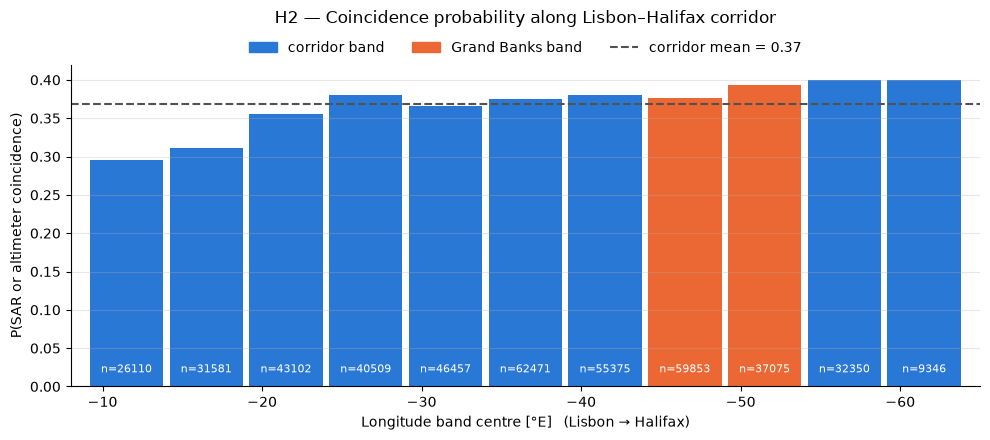

In [15]:
# ── Section 3.4: H1 and H2 statistics
# Merges catalogue + SAR + altimeter results per event, computes coincidence probabilities
# overall (H1) and per 5° longitude band (H2). Saves data/coincidence_by_lon_bin.csv and
# figures/h2_coincidence_by_segment.png.
def _p(mask):
    return float(np.mean(mask)) if len(mask) else np.nan


sar_evt = (sar_results.groupby("event_id")
           .agg(sar_coincident=("coincident", "any"), sar_n_footprints=("coincident", "sum"))
           .reset_index())
merged = (catalogue.merge(sar_evt, on="event_id", how="left")
          .merge(alt_results.drop(columns=["Hs_cmems_at_event"]), on="event_id", how="left"))
merged["sar_coincident"] = merged["sar_coincident"].astype("boolean").fillna(False).astype(bool)
merged["alt_coincident"] = merged["Hs_altimeter"].notna()
merged["any_coincident"] = merged["sar_coincident"] | merged["alt_coincident"]
merged["lon"] = merged["lon"].astype(float)
merged.to_parquet(DATA_DIR / "coincidence_merged.parquet", index=False)

# ── H1: overall coincidence probability
N_EVENTS = len(merged)
P_SAR_ONLY = _p(merged["sar_coincident"])
P_ALT_ONLY = _p(merged["alt_coincident"])
P_SAR_OR_ALT = _p(merged["any_coincident"])
h1_table = pd.DataFrame({
    "source": ["SAR_only", "altimeter_only", "SAR_or_altimeter"],
    "N_coincident": [int(merged["sar_coincident"].sum()), int(merged["alt_coincident"].sum()),
                     int(merged["any_coincident"].sum())],
    "N_total_events": N_EVENTS,
    "P": [P_SAR_ONLY, P_ALT_ONLY, P_SAR_OR_ALT],
})
print("H1 — overall coincidence probability")
display(h1_table.round(3))

# H1 breakdown: one SAR mode / one altimeter mission at a time vs. the full set
sar_hits = sar_results[sar_results["coincident"]]
breakdown = [("SAR mode " + str(m), g["event_id"].nunique()) for m, g in sar_hits.groupby("sensor_mode")]
platform_sets = merged["platforms_in_window"].dropna().astype(str).str.split(",")
for plat in sorted({p for s in platform_sets for p in s}):
    breakdown.append((f"altimeter {plat}", int(platform_sets.apply(lambda s: plat in s).sum())))
h1_breakdown = pd.DataFrame(breakdown, columns=["source", "N_coincident"])
h1_breakdown["P"] = h1_breakdown["N_coincident"] / max(N_EVENTS, 1)
print("H1 — single mission / mode vs. constellation")
display(h1_breakdown.sort_values("P").round(3))

# ── H2: spatial heterogeneity along the corridor
merged["lon_bin"] = pd.cut(merged["lon"], LON_EDGES)
by_bin = (merged.groupby("lon_bin", observed=False)
          .agg(P_SAR=("sar_coincident", "mean"), P_alt=("alt_coincident", "mean"),
               P_combined=("any_coincident", "mean"), N_events=("event_id", "size")))
by_bin.insert(0, "lon_bin_center", [iv.mid for iv in by_bin.index])
by_bin = by_bin.sort_values("lon_bin_center", ascending=False).reset_index(drop=True)  # Lisbon → Halifax
by_bin.to_csv(DATA_DIR / "coincidence_by_lon_bin.csv", index=False)
display(by_bin.round(3))

in_gb = merged["lon"].between(*GRAND_BANKS_LON)
in_mid = merged["lon"].between(*MID_ATLANTIC_LON)
P_GRAND_BANKS = _p(merged.loc[in_gb, "any_coincident"])
P_MID_ATLANTIC = _p(merged.loc[in_mid, "any_coincident"])
print(f"H2 — P_combined Grand Banks {GRAND_BANKS_LON}: {P_GRAND_BANKS:.3f} (N={in_gb.sum()}) | "
      f"mid-Atlantic {MID_ATLANTIC_LON}: {P_MID_ATLANTIC:.3f} (N={in_mid.sum()})")

# Plot: P_combined per band, Grand Banks bands highlighted, corridor mean dashed
is_gb_bin = by_bin["lon_bin_center"].between(*GRAND_BANKS_LON)
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.bar(by_bin["lon_bin_center"], by_bin["P_combined"].fillna(0), width=4.6,
       color=np.where(is_gb_bin, "#eb6834", "#2a78d6"))
mean_line = ax.axhline(P_SAR_OR_ALT, ls="--", lw=1.5, color="#52514e",
                       label=f"corridor mean = {P_SAR_OR_ALT:.2f}")
for x, n in zip(by_bin["lon_bin_center"], by_bin["N_events"]):
    ax.text(x, 0.015, f"n={n}", ha="center", va="bottom", fontsize=8, color="white")
ax.legend(handles=[Patch(color="#2a78d6", label="corridor band"),
                   Patch(color="#eb6834", label="Grand Banks band"), mean_line],
          frameon=False, loc="lower center", bbox_to_anchor=(0.5, 0.99), ncol=3)
ax.set_xlim(LON_EDGES.max() + 1, LON_EDGES.min() - 1)  # Lisbon on the left, Halifax on the right
ax.set_xlabel("Longitude band centre [°E]   (Lisbon → Halifax)")
ax.set_ylabel("P(SAR or altimeter coincidence)")
ax.set_title("H2 — Coincidence probability along Lisbon–Halifax corridor", pad=30)
ax.grid(axis="y", alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig(FIG_DIR / "h2_coincidence_by_segment.png", dpi=150)
plt.show()

## 3.5 Forecast Bias at Coincident Events — H3

$\Delta H_s = H_{s,\text{altimeter}} - H_{s,\text{CMEMS at event}}$; a positive mean bias supports H3
(model underestimates peaks). Caveat: events are selected *because* the model Hs is high,
and the altimeter sample can be up to `DELTA_X_KM` / `DELTA_T_HOURS` away, so this
comparison is biased towards negative ΔHs. The collocated bias (model at the altimeter
sample) is printed alongside as a control.

N coincident events     : 139817
Mean bias   (alt − model at event): +0.077 m
Median bias (alt − model at event): +0.067 m
% events altimeter > forecast     : 56.5 %
Mean bias (alt − model collocated at altimeter sample, N=139477): +0.094 m


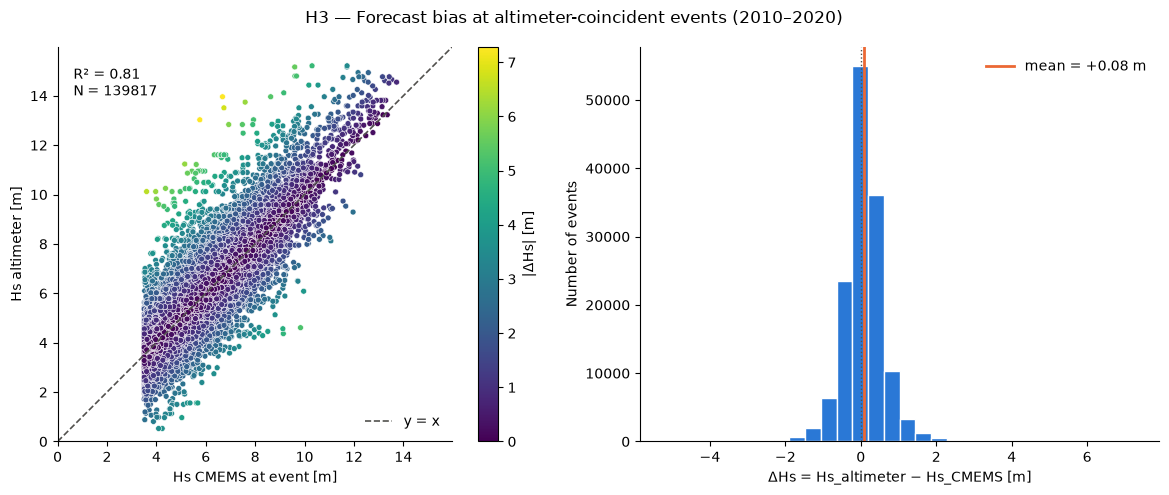

In [16]:
# ── Section 3.5: H3 forecast bias
# ΔHs = Hs_altimeter − Hs_cmems_at_event for every altimeter-coincident event.
# Prints mean / median bias and % positive, then a 2-panel figure (scatter + histogram)
# saved to figures/h3_forecast_bias.png.
# Full H3 test requires multi-year dataset; 2022 subset is indicative only.
h3 = alt_results.dropna(subset=["Hs_altimeter"]).copy()
h3["delta_Hs"] = h3["Hs_altimeter"] - h3["Hs_cmems_at_event"]
MEAN_BIAS_M = float(h3["delta_Hs"].mean()) if len(h3) else np.nan
MEDIAN_BIAS_M = float(h3["delta_Hs"].median()) if len(h3) else np.nan
PCT_ALT_ABOVE = 100 * _p(h3["delta_Hs"] > 0)
coloc = (h3["Hs_altimeter"] - h3["Hs_cmems_at_alt"]).dropna()
MEAN_BIAS_COLOC_M = float(coloc.mean()) if len(coloc) else np.nan

print(f"N coincident events     : {len(h3)}")
print(f"Mean bias   (alt − model at event): {MEAN_BIAS_M:+.3f} m")
print(f"Median bias (alt − model at event): {MEDIAN_BIAS_M:+.3f} m")
print(f"% events altimeter > forecast     : {PCT_ALT_ABOVE:.1f} %")
print(f"Mean bias (alt − model collocated at altimeter sample, N={len(coloc)}): {MEAN_BIAS_COLOC_M:+.3f} m")

if len(h3) >= 2:
    x, y = h3["Hs_cmems_at_event"].to_numpy(float), h3["Hs_altimeter"].to_numpy(float)
    r2 = np.corrcoef(x, y)[0, 1] ** 2
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
    sc = ax1.scatter(x, y, c=np.abs(h3["delta_Hs"]), cmap="viridis", s=18, edgecolor="white", linewidth=0.4)
    lim = [0, np.nanmax([x.max(), y.max()]) * 1.05]
    ax1.plot(lim, lim, "--", color="#52514e", lw=1.2, label="y = x")
    ax1.set_xlim(lim); ax1.set_ylim(lim); ax1.set_aspect("equal")
    ax1.set_xlabel("Hs CMEMS at event [m]")
    ax1.set_ylabel("Hs altimeter [m]")
    ax1.text(0.04, 0.95, f"R² = {r2:.2f}\nN = {len(h3)}", transform=ax1.transAxes, va="top")
    fig.colorbar(sc, ax=ax1, label="|ΔHs| [m]")
    ax1.legend(frameon=False, loc="lower right")
    ax2.hist(h3["delta_Hs"], bins=30, color="#2a78d6", edgecolor="white")
    ax2.axvline(MEAN_BIAS_M, color="#eb6834", lw=2, label=f"mean = {MEAN_BIAS_M:+.2f} m")
    ax2.axvline(0, color="#52514e", lw=1, ls=":")
    ax2.set_xlabel("ΔHs = Hs_altimeter − Hs_CMEMS [m]")
    ax2.set_ylabel("Number of events")
    ax2.legend(frameon=False)
    for a in (ax1, ax2):
        a.spines[["top", "right"]].set_visible(False)
    fig.suptitle(f"H3 — Forecast bias at altimeter-coincident events ({YEAR_START}–{YEAR_END})")
    fig.tight_layout()
    fig.savefig(FIG_DIR / "h3_forecast_bias.png", dpi=150)
    plt.show()
else:
    print("Not enough altimeter coincidences to plot H3.")

## 3.6 Preliminary Added Detection Value (ADV) Atlas

$\text{ADV}_\text{bin} = P_\text{combined} \times |\overline{\Delta H_s}|_\text{bin}$ — where a satellite is
both likely to be present *and* tells you something the model did not. Bins without
altimeter coincidences get $\overline{\Delta H_s} = 0$. Event counts are shown in a separate
panel below (sharing the longitude axis) rather than on a second y-axis.

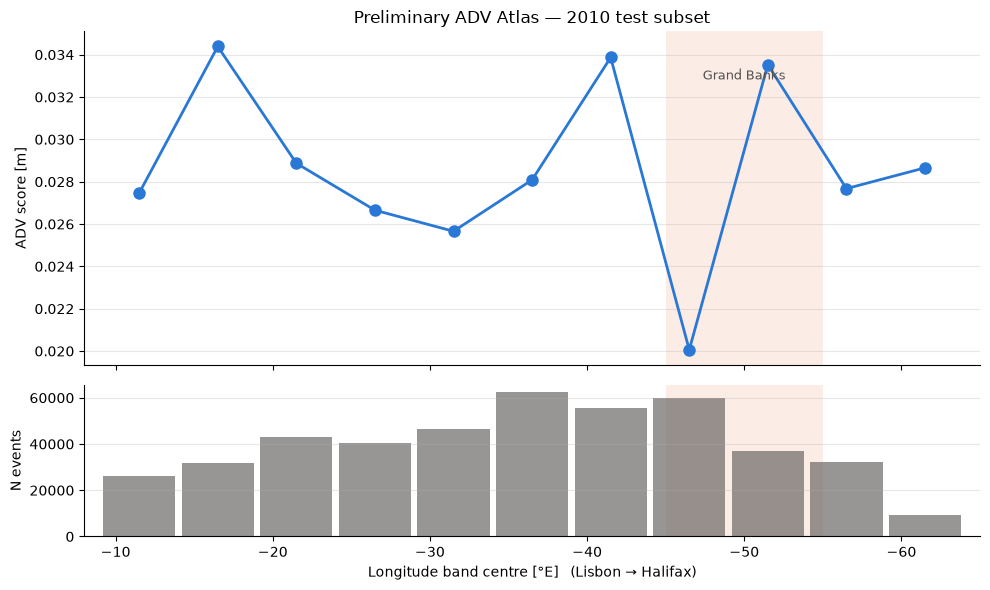

| Corridor segment | P_coincidence | Mean ΔHs [m] | ADV score |
|---|---|---|---|
| -9° to -14° | 0.295 | +0.09 | 0.027 |
| -14° to -19° | 0.312 | +0.11 | 0.034 |
| -19° to -24° | 0.356 | +0.08 | 0.029 |
| -24° to -29° | 0.380 | +0.07 | 0.027 |
| -29° to -34° | 0.366 | +0.07 | 0.026 |
| -34° to -39° | 0.375 | +0.07 | 0.028 |
| -39° to -44° | 0.380 | +0.09 | 0.034 |
| -44° to -49° (Grand Banks) | 0.377 | +0.05 | 0.020 |
| -49° to -54° (Grand Banks) | 0.393 | +0.09 | 0.034 |
| -54° to -59° | 0.400 | +0.07 | 0.028 |
| -59° to -64° | 0.400 | +0.07 | 0.029 |

Recap:
  N_EVENTS           = 444229
  P_SAR_ONLY         = 0.089
  P_ALT_ONLY         = 0.315
  P_SAR_OR_ALT       = 0.368
  P_GRAND_BANKS      = 0.385
  P_MID_ATLANTIC     = 0.371
  MEAN_BIAS_M        = 0.077
  MEDIAN_BIAS_M      = 0.067
  PCT_ALT_ABOVE      = 56.547
  MEAN_BIAS_COLOC_M  = 0.094


In [17]:
# ── Section 3.6: preliminary ADV atlas
# ADV per 5° band = P_combined × |mean ΔHs in band|; plots ADV with the Grand Banks shaded
# (event counts in a panel underneath), saves figures/adv_atlas_preliminary.png and
# prints a markdown summary table plus the recap values used in the Summary.
merged["delta_Hs"] = merged["Hs_altimeter"] - merged["Hs_cmems"]
bin_bias = merged.groupby("lon_bin", observed=False)["delta_Hs"].mean()
bias_by_center = {iv.mid: v for iv, v in bin_bias.items()}
by_bin["mean_delta_Hs"] = by_bin["lon_bin_center"].map(bias_by_center).fillna(0.0)
by_bin["ADV"] = by_bin["P_combined"].fillna(0.0) * by_bin["mean_delta_Hs"].abs()
ADV_BY_BIN = by_bin[["lon_bin_center", "P_combined", "mean_delta_Hs", "ADV", "N_events"]]
ADV_BY_BIN.to_csv(DATA_DIR / "adv_by_lon_bin.csv", index=False)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 6), sharex=True, gridspec_kw={"height_ratios": [2.2, 1]})
for a in (ax1, ax2):
    a.axvspan(*GRAND_BANKS_LON, color="#eb6834", alpha=0.12, lw=0)
    a.spines[["top", "right"]].set_visible(False)
    a.grid(axis="y", alpha=0.3)
ax1.plot(by_bin["lon_bin_center"], by_bin["ADV"], "-o", color="#2a78d6", lw=2, ms=8)
ax1.text(np.mean(GRAND_BANKS_LON), ax1.get_ylim()[1] * 0.95, "Grand Banks", ha="center", va="top",
         color="#52514e", fontsize=9)
ax1.set_ylabel("ADV score [m]")
ax1.set_title(f"Preliminary ADV Atlas — {YEAR_START} test subset")
ax2.bar(by_bin["lon_bin_center"], by_bin["N_events"], width=4.6, color="#52514e", alpha=0.6)
ax2.set_ylabel("N events")
ax2.set_xlabel("Longitude band centre [°E]   (Lisbon → Halifax)")
ax2.set_xlim(LON_EDGES.max() + 1, LON_EDGES.min() - 1)
fig.tight_layout()
fig.savefig(FIG_DIR / "adv_atlas_preliminary.png", dpi=150)
plt.show()

print("| Corridor segment | P_coincidence | Mean ΔHs [m] | ADV score |")
print("|---|---|---|---|")
for _, r in by_bin.iterrows():
    lo, hi = r["lon_bin_center"] - 2.5, r["lon_bin_center"] + 2.5
    tag = " (Grand Banks)" if GRAND_BANKS_LON[0] <= r["lon_bin_center"] <= GRAND_BANKS_LON[1] else ""
    print(f"| {hi:.0f}° to {lo:.0f}°{tag} | {r['P_combined']:.3f} | {r['mean_delta_Hs']:+.2f} | {r['ADV']:.3f} |")

print("\nRecap:")
for name in ["N_EVENTS", "P_SAR_ONLY", "P_ALT_ONLY", "P_SAR_OR_ALT", "P_GRAND_BANKS", "P_MID_ATLANTIC",
             "MEAN_BIAS_M", "MEDIAN_BIAS_M", "PCT_ALT_ABOVE", "MEAN_BIAS_COLOC_M"]:
    print(f"  {name:18s} = {globals()[name]:.3f}" if name != "N_EVENTS" else f"  {name:18s} = {N_EVENTS}")

## Summary

Numbers are printed in the *Recap* at the end of Section 3.6; the variable names below
stay valid whatever period is run.

- **H1** — `P_SAR_ONLY` (Sentinel-1 alone; S1A only in 2022) vs. `P_ALT_ONLY` vs.
  `P_SAR_OR_ALT` (`h1_table`); per-mode / per-mission breakdown in `h1_breakdown`.
  H1 is supported if single sources sit well below the combined probability.
- **H2** — `P_GRAND_BANKS` vs. `P_MID_ATLANTIC`, and the band profile in `by_bin`
  (`data/coincidence_by_lon_bin.csv`, `figures/h2_coincidence_by_segment.png`).
- **H3** — `MEAN_BIAS_M`, `MEDIAN_BIAS_M`, `PCT_ALT_ABOVE` (positive ⇒ model underestimates),
  with `MEAN_BIAS_COLOC_M` as the collocated control (`figures/h3_forecast_bias.png`).
- **ADV** — `ADV_BY_BIN` (`figures/adv_atlas_preliminary.png`).

**Limitations**
- 2022 only (one year, a single Sentinel-1 unit) — statistics are indicative.
- Hazard flag is a simplified Hs proxy (Hs > 3.5 m or Hs > 2 × 30-day mean), not the
  Phase 1 heave/roll RAO flag; the paper's abnormality index (Hmax/Hs) is not available from the reanalysis.
- Altimeters sample a ~7 km nadir line every second, whereas SAR footprints are 2-D swaths
  (IW/EW) or sparse 20 × 20 km vignettes (WV); a "coincidence" means different spatial
  coverage for each, and the 1°≈111 km circular buffer is approximate at 40–45°N.
- `Hs_cmems_at_event` is the event's peak model value; the altimeter sample can be up to
  200 km / 3 h away, which biases ΔHs negative (see the collocated control).

## Next Steps
- Extend `YEAR_START` / `YEAR_END` to 2014–2024 for full statistics.
- Plug in the `ship_physics.py` full hazard flag (heave + roll + abnormality).
- Add Sentinel-1 OSW Level-2 products for case-study Hs_max comparison.
- Feed confirmed coincidences into the Phase 4 re-routing simulation.